
# Automatic Product Category Classification

## Machine Learning Project

**Cilj projekta:**

Razviti model mašinskog učenja koji automatski
predviđa kategoriju proizvoda na osnovu njegovog naziva.

**Koraci:**
1. Učitavanje podataka
2. Istraživačka analiza (EDA)
3. Čišćenje podataka
4. Feature Engineering
5. Treniranje ML modela
6. Evaluacija i poređenje modela
7. Čuvanje finalnog modela


In [66]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
import pickle

In [67]:

# Ucitavanje CSV fajla
df = pd.read_csv("/content/sample_data/products.csv")


# Prikaz prvih 5 redova
df.head()

,product ID,Product Title,Merchant ID,Category Label,_Product Code,Number_of_Views,Merchant Rating,Listing Date
0,1,apple iphone 8 plus 64gb silver,1,Mobile Phones,QA-2276-XC,860.0,2.5,5/10/2024
1,2,apple iphone 8 plus 64 gb spacegrau,2,Mobile Phones,KA-2501-QO,3772.0,4.8,12/31/2024
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,Mobile Phones,FP-8086-IE,3092.0,3.9,11/10/2024
3,4,apple iphone 8 plus 64gb space grey,4,Mobile Phones,YI-0086-US,466.0,3.4,5/2/2022
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,Mobile Phones,NZ-3586-WP,4426.0,1.6,4/12/2023


# New Section

In [68]:

# Uklanjanje suvisnih razmaka iz naziva kolona
df.columns = df.columns.str.strip()

# Provera naziva kolona
print(df.columns.tolist())

['product ID', 'Product Title', 'Merchant ID', 'Category Label', '_Product Code', 'Number_of_Views', 'Merchant Rating', 'Listing Date']


In [69]:

# Broj redova i kolona
print("Dimenzije skupa podataka:", df.shape)

print("Broj proizvoda:", df.shape[0])
print("Broj kolona:", df.shape[1])

Dimenzije skupa podataka: (35311, 8)
Broj proizvoda: 35311
Broj kolona: 8


In [70]:

# Informacije o kolonama i tipovima podataka
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35311 entries, 0 to 35310
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   product ID       35311 non-null  int64  
 1   Product Title    35139 non-null  object 
 2   Merchant ID      35311 non-null  int64  
 3   Category Label   35267 non-null  object 
 4   _Product Code    35216 non-null  object 
 5   Number_of_Views  35297 non-null  float64
 6   Merchant Rating  35141 non-null  float64
 7   Listing Date     35252 non-null  object 
dtypes: float64(2), int64(2), object(4)
memory usage: 2.2+ MB


In [71]:

# Broj nedostajucih vrednosti po kolonama
print(df.isnull().sum())

product ID           0
Product Title      172
Merchant ID          0
Category Label      44
_Product Code       95
Number_of_Views     14
Merchant Rating    170
Listing Date        59
dtype: int64


In [72]:

# Broj razlicitih kategorija
print("Broj kategorija:")
print(df["Category Label"].nunique())

# Broj proizvoda u svakoj kategoriji
print("\nProizvodi po kategorijama:")
print(df["Category Label"].value_counts())

Broj kategorija:
13

Proizvodi po kategorijama:
Category Label
Fridge Freezers     5495
Washing Machines    4036
Mobile Phones       4020
CPUs                3771
TVs                 3564
Fridges             3457
Dishwashers         3418
Digital Cameras     2696
Microwaves          2338
Freezers            2210
fridge               123
CPU                   84
Mobile Phone          55
Name: count, dtype: int64


In [73]:
print(df.shape)
print(df.isnull().sum())
print(df["Category Label"].value_counts())

(35311, 8)
product ID           0
Product Title      172
Merchant ID          0
Category Label      44
_Product Code       95
Number_of_Views     14
Merchant Rating    170
Listing Date        59
dtype: int64
Category Label
Fridge Freezers     5495
Washing Machines    4036
Mobile Phones       4020
CPUs                3771
TVs                 3564
Fridges             3457
Dishwashers         3418
Digital Cameras     2696
Microwaves          2338
Freezers            2210
fridge               123
CPU                   84
Mobile Phone          55
Name: count, dtype: int64



# 2. Exploratory Data Analysis (EDA)

U ovoj fazi analiziramo skup podataka kako bismo
razumeli njegovu strukturu, kvalitet i raspodelu kategorija.

Ciljevi analize:
- Provera dimenzija skupa podataka
- Analiza nedostajucih vrednosti
- Provera duplikata
- Analiza kategorija proizvoda
- Vizualizacija raspodele kategorija
- Analiza duzine naziva proizvoda


In [74]:

# Dimenzije skupa podataka

print("Broj proizvoda:", df.shape[0])
print("Broj kolona:", df.shape[1])


Broj proizvoda: 35311
Broj kolona: 8


In [75]:

# Provera nedostajucih vrednosti

missing_values = df.isnull().sum()

print(missing_values)


product ID           0
Product Title      172
Merchant ID          0
Category Label      44
_Product Code       95
Number_of_Views     14
Merchant Rating    170
Listing Date        59
dtype: int64



### Analiza nedostajucih vrednosti

Proveravamo prisustvo nedostajucih vrednosti kako bismo
utvrdili da li je potrebno ciscenje podataka.

Posebnu paznju posvecujemo kolonama Product Title
i Category Label jer predstavljaju ulaznu promenljivu
i ciljnu kategoriju naseg ML modela.


In [76]:

# Provera potpuno identicnih redova

print("Broj dupliranih redova:", df.duplicated().sum())

# Provera ponovljenih naziva proizvoda
print(
    "Broj ponovljenih naziva proizvoda:",
    df["Product Title"].duplicated().sum()
)


Broj dupliranih redova: 0
Broj ponovljenih naziva proizvoda: 4450


In [77]:

# Broj razlicitih kategorija

print("Broj kategorija:", df["Category Label"].nunique())

# Broj proizvoda po kategorijama

category_counts = df["Category Label"].value_counts()

print(category_counts)


Broj kategorija: 13
Category Label
Fridge Freezers     5495
Washing Machines    4036
Mobile Phones       4020
CPUs                3771
TVs                 3564
Fridges             3457
Dishwashers         3418
Digital Cameras     2696
Microwaves          2338
Freezers            2210
fridge               123
CPU                   84
Mobile Phone          55
Name: count, dtype: int64


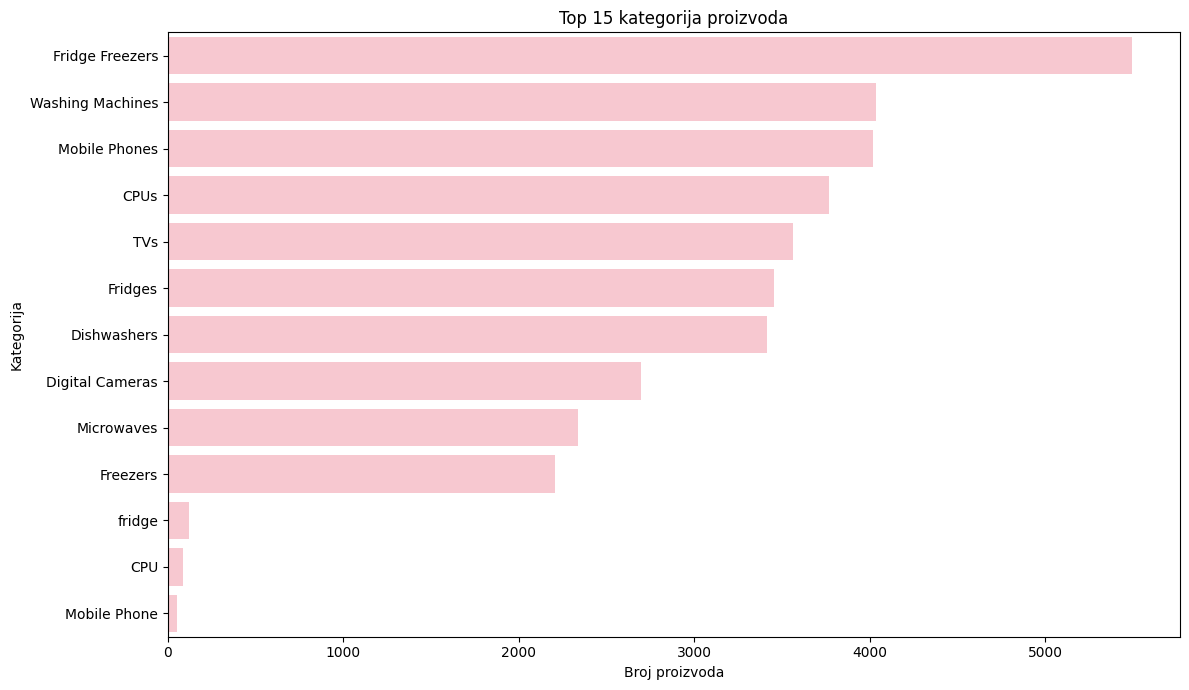

In [78]:

# Prikaz 15 najzastupljenijih kategorija

plt.figure(figsize=(12, 7))

top_categories = df["Category Label"].value_counts().head(15)

sns.barplot(
    x=top_categories.values,
    y=top_categories.index,
    color="pink"
)

plt.title("Top 15 kategorija proizvoda")
plt.xlabel("Broj proizvoda")
plt.ylabel("Kategorija")

plt.tight_layout()
plt.show()


In [79]:

# Kreiranje nove kolone sa duzinom naziva proizvoda

df["title_length"] = (
    df["Product Title"].fillna("").astype(str).str.len()
)

# Osnovna statistika

print(df["title_length"].describe())


count    35311.000000
mean        52.723627
std         22.685507
min          0.000000
25%         38.000000
50%         52.000000
75%         65.000000
max        200.000000
Name: title_length, dtype: float64


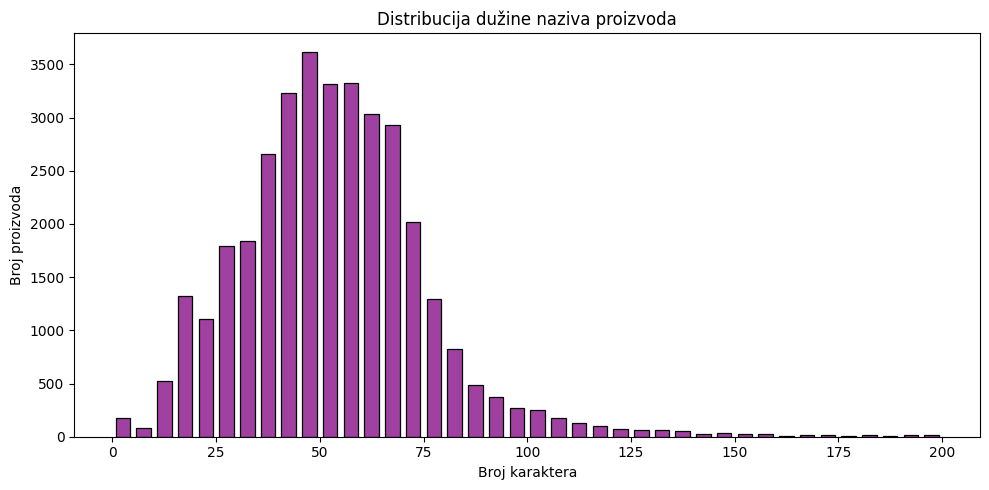

In [80]:

# Histogram duzine naziva proizvoda

plt.figure(figsize=(10, 5))

sns.histplot(
    df["title_length"],
    bins=40,
    color="purple",
    shrink=0.7
)

plt.title("Distribucija dužine naziva proizvoda")
plt.xlabel("Broj karaktera")
plt.ylabel("Broj proizvoda")
plt.tight_layout()
plt.show()


In [81]:

print("Dimenzije:", df.shape)

print("\nNedostajuce vrednosti:")
print(df.isnull().sum())

print("\nBroj kategorija:")
print(df["Category Label"].nunique())


Dimenzije: (35311, 9)

Nedostajuce vrednosti:
product ID           0
Product Title      172
Merchant ID          0
Category Label      44
_Product Code       95
Number_of_Views     14
Merchant Rating    170
Listing Date        59
title_length         0
dtype: int64

Broj kategorija:
13



# 3. Data Cleaning

U ovoj fazi pripremamo podatke za treniranje ML modela.

Postupak:
1. Izdvajanje relevantnih kolona
2. Uklanjanje nedostajucih vrednosti
3. Uklanjanje praznih naziva
4. Standardizacija teksta
5. Provera duplikata i konfliktnih kategorija

Za klasifikaciju koristimo Product Title kao ulaznu
promenljivu (X), a Category Label kao ciljnu promenljivu (y).


In [82]:

# Kreiramo kopiju originalnog skupa podataka
df_clean = df.copy()

# Zadrzavamo samo kolone potrebne za model
df_clean = df_clean[
    ["Product Title", "Category Label"]
]

print(df_clean.shape)
df_clean.head()


(35311, 2)


,Product Title,Category Label
0,apple iphone 8 plus 64gb silver,Mobile Phones
1,apple iphone 8 plus 64 gb spacegrau,Mobile Phones
2,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,Mobile Phones
3,apple iphone 8 plus 64gb space grey,Mobile Phones
4,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,Mobile Phones


In [83]:

# Broj redova pre ciscenja
print("Pre ciscenja:", len(df_clean))

# Uklanjanje redova bez naziva ili kategorije
df_clean = df_clean.dropna(
    subset=["Product Title", "Category Label"]
).copy()

# Broj redova nakon ciscenja
print("Posle ciscenja:", len(df_clean))


Pre ciscenja: 35311
Posle ciscenja: 35096


In [84]:

# Pretvaranje naziva proizvoda u mala slova
df_clean["Product Title"] = (
    df_clean["Product Title"]
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Uklanjanje suvisnih razmaka iz kategorija
df_clean["Category Label"] = (
    df_clean["Category Label"]
    .astype(str)
    .str.strip()
)

# Uklanjanje praznih naziva i kategorija
df_clean = df_clean[
    (df_clean["Product Title"] != "") &
    (df_clean["Category Label"] != "")
].copy()

df_clean.head()


,Product Title,Category Label
0,apple iphone 8 plus 64gb silver,Mobile Phones
1,apple iphone 8 plus 64 gb spacegrau,Mobile Phones
2,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,Mobile Phones
3,apple iphone 8 plus 64gb space grey,Mobile Phones
4,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,Mobile Phones


In [85]:

# Broj potpuno istih parova naziv-kategorija
print(
    "Duplirani parovi:",
    df_clean.duplicated().sum()
)

# Broj naziva sa vise razlicitih kategorija
conflicts = (
    df_clean.groupby("Product Title")["Category Label"]
    .nunique()
)

conflicting_titles = conflicts[conflicts > 1]

print(
    "Nazivi sa konfliktnim kategorijama:",
    len(conflicting_titles)
)

# Prikaz primera konfliktnih naziva
df_clean[
    df_clean["Product Title"].isin(
        conflicting_titles.index
    )
].sort_values("Product Title").head(20)


Duplirani parovi: 4210
Nazivi sa konfliktnim kategorijama: 62


,Product Title,Category Label
8101,amd ad9800ahabbox cpu cooler amd socket a12 98...,CPUs
8099,amd ad9800ahabbox cpu cooler amd socket a12 98...,CPU
33365,amica uc1503 60cm built under larder fridge,Fridges
33368,amica uc1503 60cm built under larder fridge,fridge
33366,amica uc1503 60cm built under larder fridge,Fridges
1141,archos diamond gamma 5.5 dual sim 4g 3gb 32gb ...,Mobile Phones
1145,archos diamond gamma 5.5 dual sim 4g 3gb 32gb ...,Mobile Phone
35196,blomberg kgm9550 fridge freezer,Fridges
31700,blomberg kgm9550 fridge freezer,Fridge Freezers
32101,blomberg tsm1551p,Fridges



### Zakljucci Data Cleaning faze

Originalni skup podataka sadrzi 35.311 proizvoda
rasporedjenih u 13 kategorija.

Analizom nedostajucih vrednosti utvrdjeno je:
- 172 nedostajuce vrednosti u Product Title
- 44 nedostajuce vrednosti u Category Label

Za modelovanje su izdvojene samo dve relevantne kolone:
Product Title i Category Label.

Redovi sa nedostajucim ili praznim nazivom ili kategorijom
uklonjeni su iz skupa za treniranje.

Nazivi proizvoda standardizovani su pretvaranjem u mala
slova i uklanjanjem suvisnih razmaka.

Brojevi i oznake modela su sacuvani jer mogu sadrzati
korisne informacije za klasifikaciju.

Pre daljeg modelovanja proveravaju se ponovljeni nazivi
i eventualno konfliktne kategorije.


In [86]:

print("Broj proizvoda nakon ciscenja:", len(df_clean))

print(
    "Broj dupliranih parova:",
    df_clean.duplicated().sum()
)

print(
    "Broj naziva sa konfliktnim kategorijama:",
    len(conflicting_titles)
)

print(
    "Broj kategorija:",
    df_clean["Category Label"].nunique()
)


Broj proizvoda nakon ciscenja: 35096
Broj dupliranih parova: 4210
Broj naziva sa konfliktnim kategorijama: 62
Broj kategorija: 13


In [87]:

# Uklanjanje potpuno identicnih parova
# Product Title + Category Label

print("Pre uklanjanja:", len(df_clean))

df_clean = df_clean.drop_duplicates(
    subset=["Product Title", "Category Label"]
).copy()

print("Nakon uklanjanja:", len(df_clean))


Pre uklanjanja: 35096
Nakon uklanjanja: 30886


In [88]:

# Pronalazenje konfliktnih naziva

conflicts = (
    df_clean.groupby("Product Title")["Category Label"]
    .nunique()
)

conflicting_titles = conflicts[conflicts > 1]

# Prikaz konfliktnih proizvoda
conflict_examples = df_clean[
    df_clean["Product Title"].isin(
        conflicting_titles.index
    )
].sort_values("Product Title")

print("Broj konfliktnih naziva:", len(conflicting_titles))

display(conflict_examples.head(20))


Broj konfliktnih naziva: 62


,Product Title,Category Label
8101,amd ad9800ahabbox cpu cooler amd socket a12 98...,CPUs
8099,amd ad9800ahabbox cpu cooler amd socket a12 98...,CPU
33365,amica uc1503 60cm built under larder fridge,Fridges
33368,amica uc1503 60cm built under larder fridge,fridge
1141,archos diamond gamma 5.5 dual sim 4g 3gb 32gb ...,Mobile Phones
1145,archos diamond gamma 5.5 dual sim 4g 3gb 32gb ...,Mobile Phone
35196,blomberg kgm9550 fridge freezer,Fridges
31700,blomberg kgm9550 fridge freezer,Fridge Freezers
32101,blomberg tsm1551p,Fridges
34222,blomberg tsm1551p,fridge


In [89]:

# Uklanjanje svih naziva sa konfliktnim kategorijama

print("Pre uklanjanja konflikata:", len(df_clean))

df_clean = df_clean[
    ~df_clean["Product Title"].isin(
        conflicting_titles.index
    )
].copy()

print("Nakon uklanjanja konflikata:", len(df_clean))


Pre uklanjanja konflikata: 30886
Nakon uklanjanja konflikata: 30762


In [90]:

# Zavrsna provera

print("Ukupan broj proizvoda:", len(df_clean))

print(
    "Broj kategorija:",
    df_clean["Category Label"].nunique()
)

print(
    "Duplikati:",
    df_clean.duplicated().sum()
)

print(
    "Duplirani nazivi:",
    df_clean["Product Title"].duplicated().sum()
)

print(
    "Nedostajuce vrednosti:"
)

print(df_clean.isnull().sum())


Ukupan broj proizvoda: 30762
Broj kategorija: 13
Duplikati: 0
Duplirani nazivi: 0
Nedostajuce vrednosti:
Product Title     0
Category Label    0
dtype: int64



## Obrada duplikata i konfliktnih kategorija

Nakon osnovnog ciscenja podataka ostalo je 35.096
proizvoda rasporedjenih u 13 kategorija.

Identifikovano je:
- 4.210 dupliranih parova naziv-kategorija
- 62 naziva sa konfliktnim kategorijama

Identicni parovi su uklonjeni kako bi se smanjilo
ponavljanje istih primera.

Nazivi sa konfliktnim kategorijama iskljuceni su iz
modelovanja jer nije moguce pouzdano odrediti tacnu
kategoriju bez dodatne provere.

Ovakav pristup omogucava konzistentnije oznake
i smanjuje rizik od curenja podataka tokom evaluacije.

Ogranicenje:
Uklanjanje konfliktnih primera moze smanjiti
raznovrsnost skupa podataka. U produkcionom sistemu
bila bi preporucljiva rucna provera ovih slucajeva.


In [91]:

# Cuvanje ociscenog skupa podataka

df_clean.to_csv(
    "/content/products_clean.csv",
    index=False
)

print("Ocisceni podaci su sacuvani!")


Ocisceni podaci su sacuvani!


In [92]:
print("Broj proizvoda:", len(df_clean))
print("Broj kategorija:", df_clean["Category Label"].nunique())
print("Duplirani nazivi:", df_clean["Product Title"].duplicated().sum())
print("Nedostajuce vrednosti:", df_clean.isnull().sum().sum())

Broj proizvoda: 30762
Broj kategorija: 13
Duplirani nazivi: 0
Nedostajuce vrednosti: 0



# 4. Feature Engineering and Data Preparation

U ovoj fazi pripremamo podatke za treniranje
modela masinskog ucenja.

Koristimo:
- Product Title kao ulaznu promenljivu (X)
- Category Label kao ciljnu promenljivu (y)

Podatke delimo na trening i test skup.

Za pretvaranje teksta u numericke karakteristike
koristicemo TF-IDF vektorizaciju.


In [93]:
# Ulazni podaci - nazivi proizvoda
X = df_clean["Product Title"]

# Ciljna promenljiva - kategorije
y = df_clean["Category Label"]

print("Broj proizvoda:", len(X))
print("Broj kategorija:", y.nunique())

Broj proizvoda: 30762
Broj kategorija: 13


In [94]:
# Podela podataka na trening i test skup
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Trening proizvodi:", len(X_train))
print("Test proizvodi:", len(X_test))

Trening proizvodi: 24609
Test proizvodi: 6153


In [95]:
# Kreiranje TF-IDF vektorizatora
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Ucenje recnika samo na trening podacima
X_train_tfidf = tfidf.fit_transform(X_train)

# Transformacija test podataka
X_test_tfidf = tfidf.transform(X_test)

print("Trening matrica:", X_train_tfidf.shape)
print("Test matrica:", X_test_tfidf.shape)


Trening matrica: (24609, 10000)
Test matrica: (6153, 10000)


In [96]:

# Prikaz prvih 30 karakteristika

feature_names = tfidf.get_feature_names_out()

print("Broj karakteristika:", len(feature_names))

print("\nPrvih 30 karakteristika:")
print(feature_names[:30])


Broj karakteristika: 10000

Prvih 30 karakteristika:
['00' '00 ghz' '00 gt' '001' '00ghz' '00ghz s1151' '00ghz socket' '01'
 '02' '03m' '05' '06' '06 ghz' '06ghz' '0cf' '0cf with' '0ghz'
 '0ghz 800fsb' '0ghz socket' '0in' '0in lcd' '0inch' '0inch screen' '0lcd'
 '0lcd fhd' '0mp' '10' '10 16' '10 64gb' '10 auto']



### Feature Engineering - TF-IDF

Nakon ciscenja podataka dobijeno je 30.762
jedinstvenih naziva proizvoda iz 13 kategorija.

Podaci su podeljeni na:
- 80% trening podataka
- 20% test podataka

Koriscena je stratifikovana podela kako bi odnos
kategorija ostao priblizno jednak u oba skupa.

Za ekstrakciju tekstualnih karakteristika
koriscen je TF-IDF Vectorizer.

Podesavanja:
- max_features = 10000
- ngram_range = (1, 2)
- min_df = 2
- sublinear_tf = True

TF-IDF je prilagodjen iskljucivo trening skupu,
cime je spreceno curenje informacija iz test skupa.

Ovaj pristup predstavlja pocetno resenje.
Kasnije cemo uporediti i druge nacine
vektorizacije teksta.


In [97]:

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("TF-IDF trening:", X_train_tfidf.shape)
print("TF-IDF test:", X_test_tfidf.shape)

print("Broj kategorija:", y_train.nunique())


X_train: (24609,)
X_test: (6153,)
TF-IDF trening: (24609, 10000)
TF-IDF test: (6153, 10000)
Broj kategorija: 13



# 5. Model Training - Multinomial Naive Bayes

U ovoj fazi treniramo prvi model masinskog ucenja.

Koristimo Multinomial Naive Bayes algoritam,
koji je pogodan za klasifikaciju tekstualnih podataka.

Cilj je da dobijemo pocetni (baseline) rezultat
sa kojim cemo kasnije porediti druge algoritme.


In [98]:
# Kreiranje Naive Bayes modela
nb_model = MultinomialNB()

# Treniranje modela
nb_model.fit(X_train_tfidf, y_train)

print("Model je uspesno treniran!")

Model je uspesno treniran!


In [99]:

# Predvidjanje kategorija za test proizvode
y_pred_nb = nb_model.predict(X_test_tfidf)

# Prikaz prvih 10 predvidjanja
print("Predvidjene kategorije:")
print(y_pred_nb[:10])


Predvidjene kategorije:
['TVs' 'Mobile Phones' 'Dishwashers' 'Fridge Freezers' 'Fridge Freezers'
 'Washing Machines' 'Microwaves' 'Digital Cameras' 'Digital Cameras'
 'Dishwashers']


In [100]:
# Racunanje tacnosti
accuracy_nb = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Accuracy:", round(accuracy_nb, 4))
print("Accuracy (%):", round(accuracy_nb * 100, 2))

Naive Bayes Accuracy: 0.9244
Accuracy (%): 92.44


In [101]:
print(
    classification_report(
        y_test,
        y_pred_nb,
        zero_division=0
    )
)


                  precision    recall  f1-score   support

             CPU       0.00      0.00      0.00        11
            CPUs       0.98      0.99      0.99       592
 Digital Cameras       0.98      1.00      0.99       481
     Dishwashers       0.91      0.94      0.93       608
        Freezers       0.99      0.66      0.79       381
 Fridge Freezers       0.79      0.93      0.85       962
         Fridges       0.86      0.82      0.84       613
      Microwaves       0.99      0.95      0.97       419
    Mobile Phone       0.00      0.00      0.00        10
   Mobile Phones       0.98      0.99      0.99       722
             TVs       0.97      0.98      0.98       655
Washing Machines       0.97      0.94      0.95       680
          fridge       0.00      0.00      0.00        19

        accuracy                           0.92      6153
       macro avg       0.72      0.71      0.71      6153
    weighted avg       0.92      0.92      0.92      6153



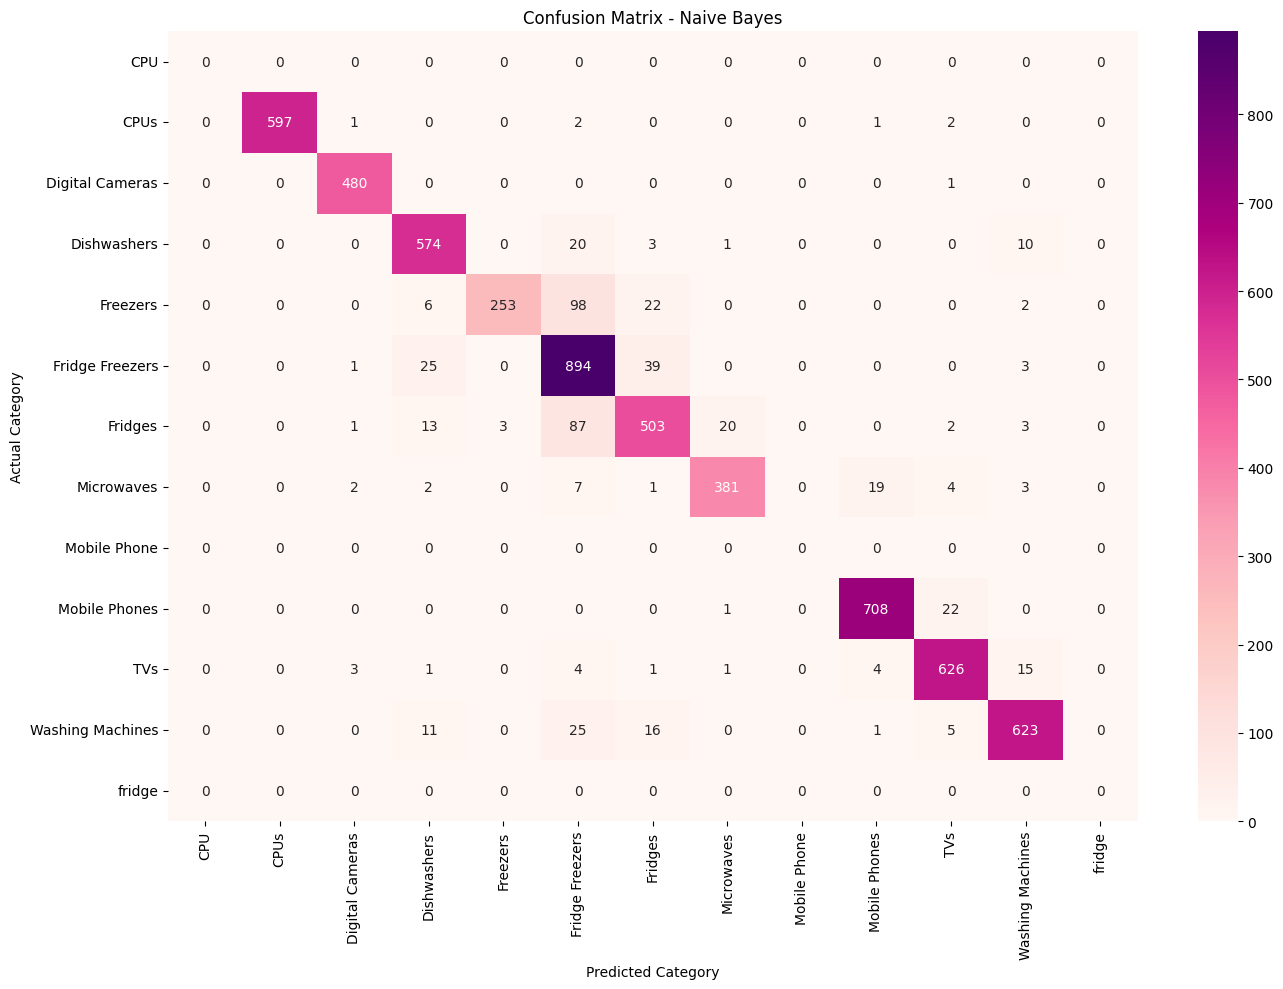

In [127]:
# Racunanje matrice zabune
cm = confusion_matrix(
    y_test,
    y_pred_nb,
    labels=nb_model.classes_
)

# Crtanje grafikona
plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="RdPu",
    xticklabels=nb_model.classes_,
    yticklabels=nb_model.classes_
)

plt.title("Confusion Matrix - Naive Bayes")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [103]:

# Test proizvodi iz zadatka
test_products = [
    "iphone 7 32gb gold,4,3,Apple iPhone 7 32GB",
    "olympus e m10 mark iii geh use silber",
    "kenwood k20mss15 solo",
    "bosch wap28390gb 8kg 1400 spin",
    "bosch serie 4 kgv39vl31g",
    "smeg sbs8004po"
]

# Pretvaranje naziva u TF-IDF karakteristike
test_vectors = tfidf.transform(test_products)

# Predvidjanje kategorija
predictions = nb_model.predict(test_vectors)

# Prikaz rezultata
for product, category in zip(test_products, predictions):
    print("Proizvod:", product)
    print("Predvidjena kategorija:", category)
    print("-" * 50)


Proizvod: iphone 7 32gb gold,4,3,Apple iPhone 7 32GB
Predvidjena kategorija: Mobile Phones
--------------------------------------------------
Proizvod: olympus e m10 mark iii geh use silber
Predvidjena kategorija: Digital Cameras
--------------------------------------------------
Proizvod: kenwood k20mss15 solo
Predvidjena kategorija: Microwaves
--------------------------------------------------
Proizvod: bosch wap28390gb 8kg 1400 spin
Predvidjena kategorija: Washing Machines
--------------------------------------------------
Proizvod: bosch serie 4 kgv39vl31g
Predvidjena kategorija: Fridge Freezers
--------------------------------------------------
Proizvod: smeg sbs8004po
Predvidjena kategorija: Fridge Freezers
--------------------------------------------------



### Baseline Model - Multinomial Naive Bayes

Kao prvi model odabran je Multinomial Naive Bayes.

Razlozi za izbor:
- Jednostavna implementacija
- Brzo treniranje
- Pogodan za TF-IDF tekstualne karakteristike
- Dobar pocetni model za poredjenje

Model je treniran na 24.609 proizvoda,
a evaluiran na 6.153 test proizvoda.

Za evaluaciju koristimo:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

Dobijeni rezultati posluzice kao pocetna referenca
za poredjenje sa drugim ML algoritmima.



# 6. Improving Data Quality - Category Standardization

Analizom prvog modela uoceno je da postoje
razliciti nazivi za iste kategorije.

Primeri:
- CPU i CPUs
- Mobile Phone i Mobile Phones
- fridge i Fridges

Ove kategorije standardizujemo kako bismo
poboljsali kvalitet ciljnih oznaka.

Prvi Naive Bayes model zadrzavamo kao baseline
za poredjenje sa poboljsanim resenjem.


In [104]:

# Pravimo novu kopiju ociscenih podataka
df_final = df_clean.copy()

# Mapa za standardizaciju kategorija
category_mapping = {
    "CPU": "CPUs",
    "Mobile Phone": "Mobile Phones",
    "fridge": "Fridges"
}

# Zamena naziva kategorija
df_final["Category Label"] = (
    df_final["Category Label"]
    .replace(category_mapping)
)

# Provera kategorija
print("Broj kategorija:", df_final["Category Label"].nunique())

print("\nKategorije:")
print(df_final["Category Label"].value_counts())


Broj kategorija: 10

Kategorije:
Category Label
Fridge Freezers     4808
Mobile Phones       3655
Washing Machines    3402
TVs                 3275
Fridges             3162
Dishwashers         3042
CPUs                3016
Digital Cameras     2405
Microwaves          2094
Freezers            1903
Name: count, dtype: int64


In [105]:

# Provera duplikata nakon standardizacije
print(
    "Duplirani nazivi:",
    df_final["Product Title"].duplicated().sum()
)

# Provera nedostajucih vrednosti
print(
    "Nedostajuce vrednosti:",
    df_final.isnull().sum().sum()
)


Duplirani nazivi: 0
Nedostajuce vrednosti: 0


In [106]:

# Definisanje ulaznih i ciljnih podataka
X = df_final["Product Title"]
y = df_final["Category Label"]

# Podela podataka
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Trening proizvodi:", len(X_train))
print("Test proizvodi:", len(X_test))
print("Broj kategorija:", y.nunique())


Trening proizvodi: 24609
Test proizvodi: 6153
Broj kategorija: 10


In [107]:

# Novi TF-IDF vektorizator
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Transformacija trening i test podataka
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Trening:", X_train_tfidf.shape)
print("Test:", X_test_tfidf.shape)


Trening: (24609, 10000)
Test: (6153, 10000)


In [108]:

# Treniranje poboljsanog Naive Bayes modela
nb_model_v2 = MultinomialNB()

nb_model_v2.fit(X_train_tfidf, y_train)

# Predvidjanje
y_pred_nb_v2 = nb_model_v2.predict(X_test_tfidf)

# Evaluacija
accuracy_nb_v2 = accuracy_score(y_test, y_pred_nb_v2)

print("Naive Bayes V2 Accuracy:",
      round(accuracy_nb_v2 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_nb_v2,
    zero_division=0
))


Naive Bayes V2 Accuracy: 93.09 %

Classification Report:
                  precision    recall  f1-score   support

            CPUs       1.00      0.99      1.00       603
 Digital Cameras       0.99      1.00      0.99       481
     Dishwashers       0.91      0.94      0.93       608
        Freezers       1.00      0.66      0.79       381
 Fridge Freezers       0.78      0.94      0.85       962
         Fridges       0.89      0.80      0.84       632
      Microwaves       0.99      0.95      0.97       419
   Mobile Phones       1.00      0.99      1.00       731
             TVs       0.98      0.99      0.98       655
Washing Machines       0.96      0.94      0.95       681

        accuracy                           0.93      6153
       macro avg       0.95      0.92      0.93      6153
    weighted avg       0.94      0.93      0.93      6153




# 7. Model Comparison - Logistic Regression

Nakon treniranja Naive Bayes modela,
testiramo Logistic Regression algoritam.

Cilj je da uporedimo performanse dva algoritma
na istom trening i test skupu.

Metrike za poredjenje:
- Accuracy
- Macro F1-score
- Weighted F1-score
- Precision i Recall po kategorijama

Posebnu paznju posvecujemo kategorijama
Freezers, Fridges i Fridge Freezers.


In [109]:
# Kreiranje Logistic Regression modela

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Treniranje modela
lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression model je treniran!")

Logistic Regression model je treniran!


In [110]:
# Predvidjanje kategorija na test skupu

y_pred_lr = lr_model.predict(X_test_tfidf)

print("Prvih 10 predvidjanja:")
print(y_pred_lr[:10])

Prvih 10 predvidjanja:
['TVs' 'Mobile Phones' 'Dishwashers' 'Freezers' 'Fridge Freezers' 'TVs'
 'Microwaves' 'Digital Cameras' 'Digital Cameras' 'Dishwashers']


In [111]:
# Racunanje tacnosti Logistic Regression modela

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:",
      round(accuracy_lr * 100, 2), "%")

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_lr,
    zero_division=0
))

Logistic Regression Accuracy: 94.91 %

Classification Report:
                  precision    recall  f1-score   support

            CPUs       1.00      0.99      1.00       603
 Digital Cameras       1.00      1.00      1.00       481
     Dishwashers       0.90      0.94      0.92       608
        Freezers       0.97      0.88      0.92       381
 Fridge Freezers       0.90      0.93      0.92       962
         Fridges       0.91      0.87      0.89       632
      Microwaves       0.98      0.95      0.97       419
   Mobile Phones       0.97      1.00      0.98       731
             TVs       0.97      0.98      0.98       655
Washing Machines       0.94      0.94      0.94       681

        accuracy                           0.95      6153
       macro avg       0.95      0.95      0.95      6153
    weighted avg       0.95      0.95      0.95      6153



In [112]:
# Kreiranje tabele za poredjenje modela

results = pd.DataFrame({
    "Model": [
        "Naive Bayes V2",
        "Logistic Regression"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_nb_v2),
        accuracy_score(y_test, y_pred_lr)
    ],
    "Macro F1": [
        f1_score(y_test, y_pred_nb_v2, average="macro"),
        f1_score(y_test, y_pred_lr, average="macro")
    ],
    "Weighted F1": [
        f1_score(y_test, y_pred_nb_v2, average="weighted"),
        f1_score(y_test, y_pred_lr, average="weighted")
    ]
})

display(results.round(4))

,Model,Accuracy,Macro F1,Weighted F1
0,Naive Bayes V2,0.9309,0.9309,0.9303
1,Logistic Regression,0.9491,0.9512,0.9490


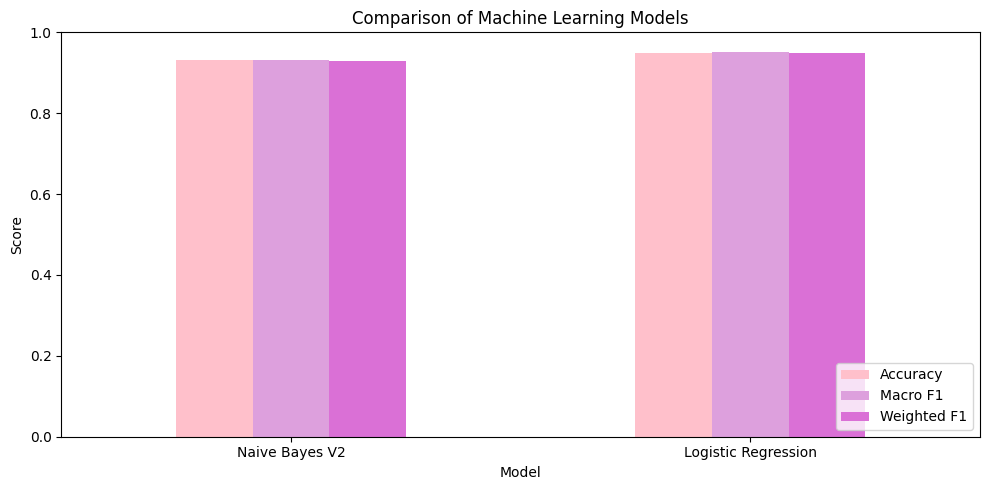

In [129]:

# Graficko poredjenje modela

results_plot = results.set_index("Model")

results_plot.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0,
    color=["pink", "plum", "orchid", "mediumpurple"]
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()


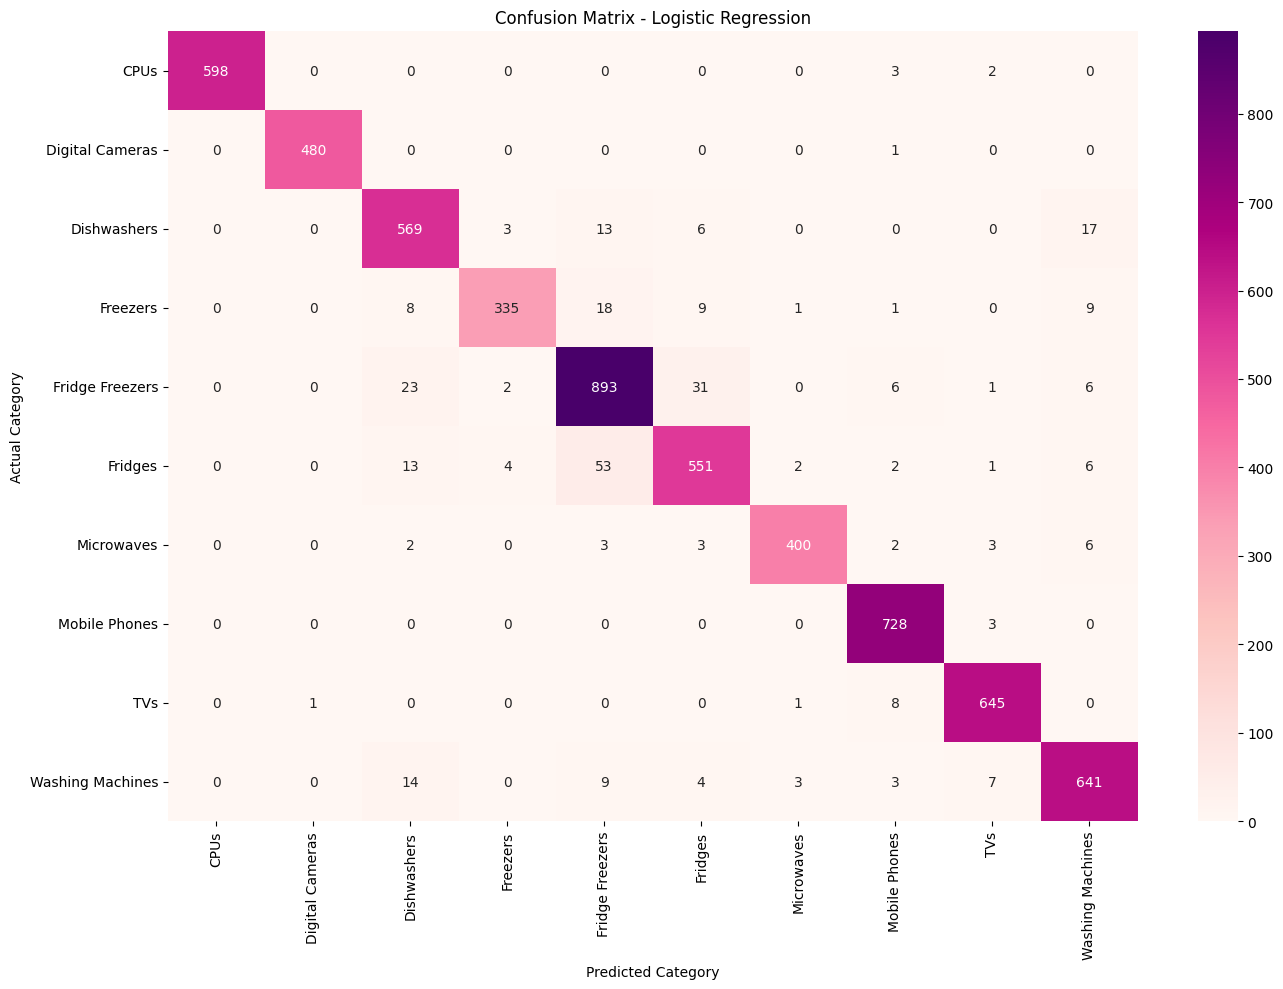

In [130]:

# Confusion Matrix za Logistic Regression

cm_lr = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=lr_model.classes_
)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="RdPu",
    xticklabels=lr_model.classes_,
    yticklabels=lr_model.classes_
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


In [115]:

# Test proizvodi iz zadatka

test_products = [
    "iphone 7 32gb gold,4,3,Apple iPhone 7 32GB",
    "olympus e m10 mark iii geh use silber",
    "kenwood k20mss15 solo",
    "bosch wap28390gb 8kg 1400 spin",
    "bosch serie 4 kgv39vl31g",
    "smeg sbs8004po"
]

# Ocekivane kategorije
expected_categories = [
    "Mobile Phones",
    "Digital Cameras",
    "Microwaves",
    "Washing Machines",
    "Fridge Freezers",
    "Fridge Freezers"
]

# Pretvaranje teksta u TF-IDF
test_vectors = tfidf.transform(test_products)

# Predvidjanje
lr_predictions = lr_model.predict(test_vectors)

# Prikaz rezultata
for product, expected, predicted in zip(
    test_products,
    expected_categories,
    lr_predictions
):
    print("Proizvod:", product)
    print("Ocekivano:", expected)
    print("Predvidjeno:", predicted)
    print("Tacno:", expected == predicted)
    print("-" * 50)


Proizvod: iphone 7 32gb gold,4,3,Apple iPhone 7 32GB
Ocekivano: Mobile Phones
Predvidjeno: Mobile Phones
Tacno: True
--------------------------------------------------
Proizvod: olympus e m10 mark iii geh use silber
Ocekivano: Digital Cameras
Predvidjeno: Digital Cameras
Tacno: True
--------------------------------------------------
Proizvod: kenwood k20mss15 solo
Ocekivano: Microwaves
Predvidjeno: Microwaves
Tacno: True
--------------------------------------------------
Proizvod: bosch wap28390gb 8kg 1400 spin
Ocekivano: Washing Machines
Predvidjeno: Washing Machines
Tacno: True
--------------------------------------------------
Proizvod: bosch serie 4 kgv39vl31g
Ocekivano: Fridge Freezers
Predvidjeno: Fridge Freezers
Tacno: True
--------------------------------------------------
Proizvod: smeg sbs8004po
Ocekivano: Fridge Freezers
Predvidjeno: Fridges
Tacno: False
--------------------------------------------------



### Logistic Regression - Model Comparison

Kao drugi algoritam testiran je Logistic Regression.

Korisceni su isti trening i test podaci,
kao i ista TF-IDF reprezentacija teksta
kao kod Naive Bayes V2 modela.

Cilj eksperimenta je da utvrdimo da li
Logistic Regression bolje razlikuje
kategorije proizvoda.

Posebno analiziramo:
- Ukupnu tacnost
- Macro F1-score
- Weighted F1-score
- Greske izmedju slicnih kategorija

Konacni izbor modela bice zasnovan na
rezultatima evaluacije i testiranju
na primerima iz zadatka.



# 8. Feature Engineering - Character N-grams

U prethodnom eksperimentu Logistic Regression
je postigao accuracy od 94.91%.

Medjutim, model je pogresno klasifikovao
proizvod "smeg sbs8004po".

Zbog toga testiramo Character N-grams pristup.

Ova metoda koristi nizove karaktera umesto
iskljucivo celih reci, sto moze biti korisno
za tehnicke oznake i sifre proizvoda.


In [116]:

# Character N-grams TF-IDF

tfidf_char = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=2,
    max_features=20000,
    sublinear_tf=True
)

# Ucenje samo na trening podacima
X_train_char = tfidf_char.fit_transform(X_train)

# Transformacija test podataka
X_test_char = tfidf_char.transform(X_test)

print("Trening matrica:", X_train_char.shape)
print("Test matrica:", X_test_char.shape)


Trening matrica: (24609, 20000)
Test matrica: (6153, 20000)


In [117]:

# Logistic Regression sa Character N-grams

lr_char_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_char_model.fit(X_train_char, y_train)

# Predvidjanje
y_pred_char = lr_char_model.predict(X_test_char)

# Evaluacija
accuracy_char = accuracy_score(y_test, y_pred_char)

print(
    "Character N-grams Accuracy:",
    round(accuracy_char * 100, 2), "%"
)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_char,
    zero_division=0
))


Character N-grams Accuracy: 97.94 %

Classification Report:
                  precision    recall  f1-score   support

            CPUs       1.00      0.99      1.00       603
 Digital Cameras       1.00      1.00      1.00       481
     Dishwashers       0.99      0.98      0.98       608
        Freezers       0.99      0.92      0.95       381
 Fridge Freezers       0.96      0.98      0.97       962
         Fridges       0.93      0.95      0.94       632
      Microwaves       1.00      0.99      0.99       419
   Mobile Phones       0.99      1.00      0.99       731
             TVs       0.99      1.00      0.99       655
Washing Machines       0.98      0.98      0.98       681

        accuracy                           0.98      6153
       macro avg       0.98      0.98      0.98      6153
    weighted avg       0.98      0.98      0.98      6153



In [118]:

# Tabela za poredjenje modela

comparison = pd.DataFrame({
    "Model": [
        "Naive Bayes",
        "Logistic Regression",
        "Logistic Regression Char"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_nb_v2),
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_char)
    ],
    "Macro F1": [
        f1_score(y_test, y_pred_nb_v2, average="macro"),
        f1_score(y_test, y_pred_lr, average="macro"),
        f1_score(y_test, y_pred_char, average="macro")
    ]
})

display(comparison.round(4))


,Model,Accuracy,Macro F1
0,Naive Bayes,0.9309,0.9309
1,Logistic Regression,0.9491,0.9512
2,Logistic Regression Char,0.9794,0.9796


In [119]:

# Transformacija test proizvoda
test_vectors_char = tfidf_char.transform(test_products)

# Predvidjanje
char_predictions = lr_char_model.predict(test_vectors_char)

# Prikaz rezultata
for product, expected, predicted in zip(
    test_products,
    expected_categories,
    char_predictions
):
    print("Proizvod:", product)
    print("Ocekivano:", expected)
    print("Predvidjeno:", predicted)
    print("Tacno:", expected == predicted)
    print("-" * 50)


Proizvod: iphone 7 32gb gold,4,3,Apple iPhone 7 32GB
Ocekivano: Mobile Phones
Predvidjeno: Mobile Phones
Tacno: True
--------------------------------------------------
Proizvod: olympus e m10 mark iii geh use silber
Ocekivano: Digital Cameras
Predvidjeno: Digital Cameras
Tacno: True
--------------------------------------------------
Proizvod: kenwood k20mss15 solo
Ocekivano: Microwaves
Predvidjeno: Microwaves
Tacno: True
--------------------------------------------------
Proizvod: bosch wap28390gb 8kg 1400 spin
Ocekivano: Washing Machines
Predvidjeno: Washing Machines
Tacno: True
--------------------------------------------------
Proizvod: bosch serie 4 kgv39vl31g
Ocekivano: Fridge Freezers
Predvidjeno: Fridge Freezers
Tacno: True
--------------------------------------------------
Proizvod: smeg sbs8004po
Ocekivano: Fridge Freezers
Predvidjeno: Dishwashers
Tacno: False
--------------------------------------------------



### Character N-grams Experiment

Nakon evaluacije Logistic Regression modela
primeceno je da model ima poteskoca sa
odredjenim tehnickim oznakama proizvoda.

Zbog toga je testirana TF-IDF vektorizacija
zasnovana na nizovima karaktera duzine 3 do 5.

Koriscen je Logistic Regression klasifikator
sa istim trening i test skupom.

Cilj eksperimenta je da proverimo da li
karakteristike zasnovane na delovima reci
poboljsavaju klasifikaciju proizvoda.

Rezultate uporedjujemo sa prethodnim modelima
pomocu Accuracy i Macro F1-score.



# 9. Final Model - Pipeline and Model Saving

Na osnovu rezultata evaluacije izabran je
Logistic Regression sa Character N-grams.

Model je postigao accuracy od 97.94%
na postojecem test skupu.

Za jednostavniju primenu koristimo
scikit-learn Pipeline koji povezuje:

1. TF-IDF Character Vectorizer
2. Logistic Regression klasifikator

Kompletan Pipeline cuvamo u .pkl formatu.


In [120]:

from sklearn.pipeline import Pipeline

# Kreiranje kompletnog ML Pipeline-a
final_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(3, 5),
        min_df=2,
        max_features=20000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Pipeline je uspesno kreiran!")


Pipeline je uspesno kreiran!


In [121]:

# Treniranje kompletnog Pipeline-a

final_pipeline.fit(X_train, y_train)

print("Finalni Pipeline je uspesno treniran!")


Finalni Pipeline je uspesno treniran!


In [122]:

# Predvidjanje na test skupu
pipeline_predictions = final_pipeline.predict(X_test)

# Provera tacnosti
pipeline_accuracy = accuracy_score(
    y_test,
    pipeline_predictions
)

print(
    "Pipeline Accuracy:",
    round(pipeline_accuracy * 100, 2), "%"
)


Pipeline Accuracy: 97.94 %


In [123]:
# Cuvanje kompletnog modela
with open("/content/product_classifier.pkl", "wb") as file:
    pickle.dump(final_pipeline, file)

print("Model je sacuvan kao product_classifier.pkl")

Model je sacuvan kao product_classifier.pkl


In [124]:

# Ucitavanje sacuvanog modela

with open("/content/product_classifier.pkl", "rb") as file:
    loaded_model = pickle.load(file)

# Test predvidjanje
product = ["apple iphone 7 32gb gold"]

prediction = loaded_model.predict(product)

print("Proizvod:", product[0])
print("Predvidjena kategorija:", prediction[0])


Proizvod: apple iphone 7 32gb gold
Predvidjena kategorija: Mobile Phones


In [125]:

from google.colab import files

files.download("/content/product_classifier.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


### Final Model Selection

Nakon poredjenja vise algoritama izabran je
Logistic Regression sa Character N-grams.

Rezultati na postojecem test skupu:

- Accuracy: 97.94%
- Macro F1-score: 0.9796
- Broj kategorija: 10
- Broj test proizvoda: 6153

Model koristi TF-IDF vektorizaciju sa nizovima
karaktera duzine 3 do 5.

Za jednostavniju primenu kreiran je Pipeline
koji sadrzi vektorizator i klasifikator.

Pipeline je sacuvan u fajlu:
product_classifier.pkl

Model je namenjen automatskom predlaganju
kategorije proizvoda na osnovu naziva.

Ogranicenje:
Model moze pogresiti kod kratkih naziva
koji sadrze samo brend i sifru proizvoda.
